# Revenue Bridge (Price / Volume / Mix / FX)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

A waterfall that walks from last year's revenue to this year's, one driver at a time: price, volume, product mix, currency and acquisitions. It answers the CFO's question 'why did revenue change?' and separates organic from inorganic and currency effects.

## When to use

- Explain the change in revenue, profit or margin between two periods
- Separate organic growth from FX and M&A effects in earnings reviews
- Communicate a budget-vs-actual variance by driver

## Avoid when

- Drivers are not additive or overlap (decompose them consistently first)
- There are more than ~8 drivers (group the small ones into 'Other')
- Truncating the y-axis to exaggerate small steps; choose a period where the drivers are material, or chart the drivers alone

## Alternatives

- Diverging bar of drivers only
- Table with driver contributions

## Design tips

- Color increases and decreases in two opposing hues, and keep totals neutral
- Draw thin connector lines between steps so the eye follows the running total
- Label every step with its signed value, and the totals with their levels

## Example

A fictional company's revenue moving from $400m (FY2024) to $515m (FY2025) (illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
drivers = pd.DataFrame({
    "step": ["FY2024", "Price", "Volume", "Mix", "FX", "Acquisitions", "FY2025"],
    "value_m": [400, 45, 70, -25, -35, 60, np.nan],
})
drivers.loc[drivers.index[-1], "value_m"] = drivers["value_m"].iloc[:-1].sum()
drivers

,step,value_m
0,FY2024,400.0
1,Price,45.0
2,Volume,70.0
3,Mix,-25.0
4,FX,-35.0
5,Acquisitions,60.0
6,FY2025,515.0


### Plot

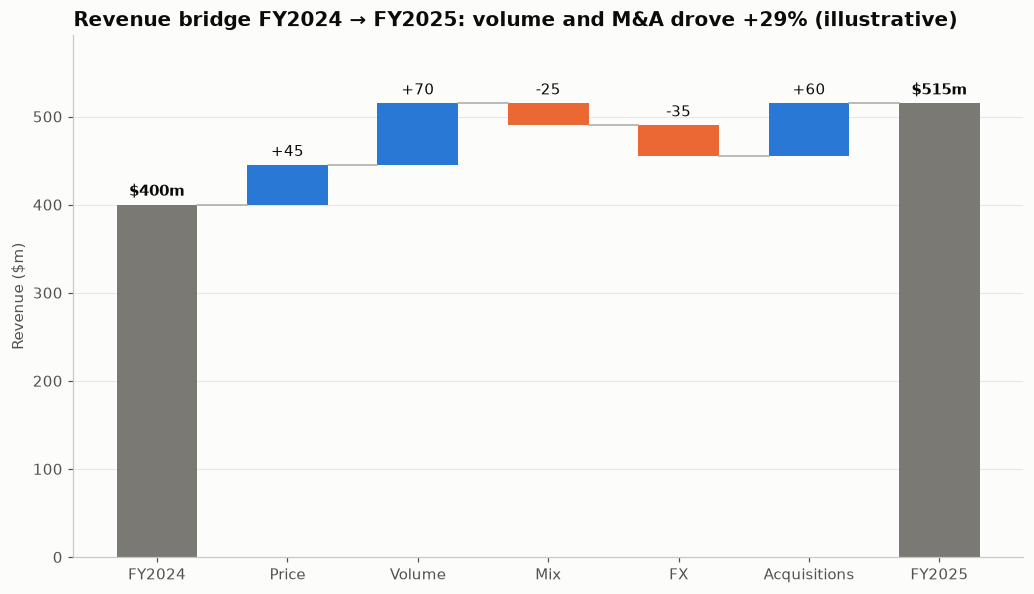

In [3]:
vals = drivers["value_m"].to_numpy()
is_total = np.zeros(len(vals), bool)
is_total[[0, -1]] = True
running = np.r_[0, np.cumsum(vals[:-1])]
bottom = np.where(is_total, 0, np.where(vals >= 0, running, running + vals))
height = np.where(is_total, vals, np.abs(vals))
colors = np.where(is_total, "#7a7974", np.where(vals >= 0, PALETTE[0], PALETTE[1]))

fig, ax = plt.subplots(figsize=(9.5, 5.5))
x = np.arange(len(vals))
ax.bar(x, height, bottom=bottom, color=colors, width=0.62)
for i in range(len(vals) - 1):                    # connectors at the running total
    level = vals[0] if i == 0 else running[i] + vals[i]
    ax.plot([i + 0.31, i + 0.69], [level, level], color="#a9a8a2", linewidth=1)
for xi, v, b, h, tot in zip(x, vals, bottom, height, is_total):
    label = f"${v:,.0f}m" if tot else f"{v:+,.0f}"
    ax.text(xi, b + h + 6, label, ha="center", va="bottom", fontsize=10,
            fontweight="bold" if tot else "normal")
ax.set_xticks(x, drivers["step"])
ax.set_ylim(0, vals.max() * 1.15)
ax.set_ylabel("Revenue ($m)")
ax.grid(axis="x", visible=False)
ax.set_title("Revenue bridge FY2024 → FY2025: volume and M&A drove +29% (illustrative)")
fig.tight_layout()
plt.show()

## How to read it

Start at the gray FY2024 bar. Each blue step adds revenue and each orange step removes it. Higher volume and the acquisition drove most of the growth, while currency and an unfavourable mix took some back.

---
Standalone script: [`revenue_bridge.py`](revenue_bridge.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)